# Experiment 8: LoRA transfer and retention

How do low-rank query/value updates affect predictive quality on excluded credit tables, and what happens to non-credit retention? Report every planned learning rate against its own original checkpoint. The five-fold benchmark uses matched inference settings within this experiment, including FP32 without FA3 for TabICL. The earlier full/frozen grid stays separate unless its protocol and artifact provenance match.

## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, lora_study as ls, publication as pub
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment8/02_results')
report = cp.NotebookReport('Experiment 8: LoRA transfer and retention', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Original versus LoRA comparisons describe the fixed experiment-8 recipe; no best-rate selection is performed on the reported held-out scores.')
runs = [cp.load_campaign(8, track) for track in ('pd', 'lgd')]
from src.visualize import comparisons as cmp, dashboards as db


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Checkpoint and paired evaluation coverage

In [2]:
for run in runs:
    report.table(run.track.upper()+' protocol', ls.protocol_table(run))
    report.table(run.track.upper()+' evidence', pub.availability(run))
    report.table(run.track.upper()+' planned and recorded trials', ls.coverage_table(run))
    report.table(run.track.upper()+' paired benchmark coverage', cmp.benchmark_coverage(run))
report.add('1. Checkpoint and paired evaluation coverage', 'Every trained/original comparison requires all five finite outer folds. Non-credit tables also require all four training partitions. A pending roster or absent figure is not a zero effect and does not indicate whether a remote job is running.')

,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,PD
2,Adaptation,Low-rank updates to all attention query/value ...
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA produc...
8,Learning rates,"1e-05, 0.0001, 0.001"
9,L2-SP,0


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,18888,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1815,Project final evaluation


,base,learning_rate,planned,completed,recorded_outcomes,evidence
0,TabICLv2,0.00001,4,4,OK: 4,Recorded local outcomes
1,TabICLv2,0.00010,4,4,OK: 4,Recorded local outcomes
2,TabICLv2,0.00100,4,4,OK: 4,Recorded local outcomes
3,TabPFN v3,0.00001,4,4,OK: 4,Recorded local outcomes
4,TabPFN v3,0.00010,4,4,OK: 4,Recorded local outcomes
5,TabPFN v3,0.00100,4,4,OK: 4,Recorded local outcomes


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,51,17
1,credit,TabPFN v3,12,12,51,17
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,LGD
2,Adaptation,Low-rank updates to all attention query/value ...
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA produc...
8,Learning rates,"1e-05, 0.0001, 0.001"
9,L2-SP,0


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,40032,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1320,Project final evaluation


,base,learning_rate,planned,completed,recorded_outcomes,evidence
0,TabICLv2,0.00001,4,4,OK: 4,Recorded local outcomes
1,TabICLv2,0.00010,4,4,OK: 4,Recorded local outcomes
2,TabICLv2,0.00100,4,4,OK: 4,Recorded local outcomes
3,TabPFN v3,0.00001,4,4,OK: 4,Recorded local outcomes
4,TabPFN v3,0.00010,4,4,OK: 4,Recorded local outcomes
5,TabPFN v3,0.00100,4,4,OK: 4,Recorded local outcomes


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,24,8
1,credit,TabPFN v3,12,12,24,8
2,ood,TabICLv2,12,12,48,4
3,ood,TabPFN v3,12,12,48,4


## 2. Original and LoRA predictive quality

AUC for PD and R² for LGD are shown as equal-table means against learning rate. Each panel uses the same available table cohort at all three rates; credit transfer and non-credit retention remain separate.

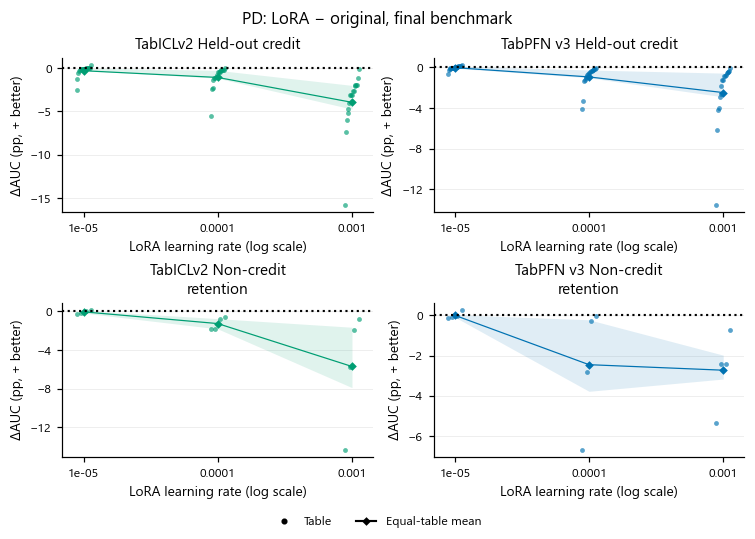

Experiment 8, final five-fold benchmark: paired change in AUC (ΔAUC (pp, + better)) of rank-16 query/value LoRA CPT relative to the original checkpoint of the same base, at the three LoRA learning rates (logarithmic axis). Upper panels: held-out credit tables; lower panels: the four same-task non-credit retention tables, each first averaged over all four CPT partitions. Points are tables, the line connects equal-table means across rates (not a training curve) and the band spans the table interquartile range (heterogeneity, not a confidence interval). All rates share one complete table cohort per panel, each adapted/original pair has five matched outer folds, and original and LoRA inference settings match (FP32 without FA3 for TabICLv2). Positive values favour LoRA. Absolute original and LoRA scores are retained in the accompanying tables; no rate is selected.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Bondora Peer-to-Peer,credit,roc_auc,-0.001725,0.897219,0.895494,1
1,TabICLv2,0.00001,0.0,True,one_sample,Cobranded,credit,roc_auc,-0.000387,0.842712,0.842325,1
2,TabICLv2,0.00001,0.0,True,one_sample,Credit Risk,credit,roc_auc,-0.012324,0.955257,0.942932,1
3,TabICLv2,0.00001,0.0,True,one_sample,GMSC,credit,roc_auc,-0.000801,0.867210,0.866409,1
4,TabICLv2,0.00001,0.0,True,one_sample,German Credit,credit,roc_auc,0.003325,0.790140,0.793466,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.00100,0.0,True,one_sample,PropPD2,credit,roc_auc,-0.005109,0.657331,0.652222,1
98,TabPFN v3,0.00100,0.0,True,one_sample,SBA Loans Case,credit,roc_auc,-0.005759,0.989833,0.984074,1
99,TabPFN v3,0.00100,0.0,True,one_sample,Taiwan Credit Card,credit,roc_auc,-0.008432,0.789665,0.781233,1
100,TabPFN v3,0.00100,0.0,True,one_sample,Thomas,credit,roc_auc,-0.026510,0.651588,0.625077,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46905,ood,roc_auc,-0.003190,0.845801,0.842610,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46947,ood,roc_auc,-0.001467,0.936670,0.935203,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46952,ood,roc_auc,0.000528,0.940093,0.940621,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46956,ood,roc_auc,0.001603,0.776168,0.777771,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46905,ood,roc_auc,-0.018081,0.845801,0.827720,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46947,ood,roc_auc,-0.006068,0.936670,0.930602,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46952,ood,roc_auc,-0.008183,0.940093,0.931910,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46956,ood,roc_auc,-0.018692,0.776168,0.757476,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46905,ood,roc_auc,-0.143197,0.845801,0.702604,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46947,ood,roc_auc,-0.019248,0.936670,0.917422,4


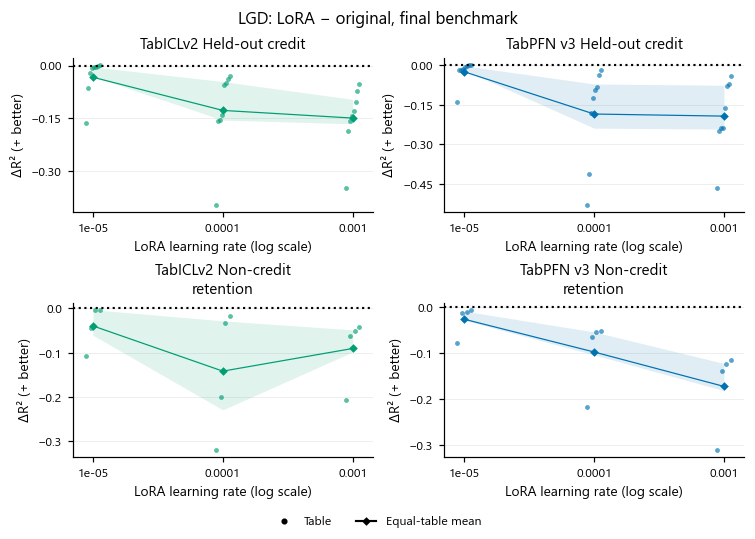

Experiment 8, final five-fold benchmark: paired change in R² (ΔR² (+ better)) of rank-16 query/value LoRA CPT relative to the original checkpoint of the same base, at the three LoRA learning rates (logarithmic axis). Upper panels: held-out credit tables; lower panels: the four same-task non-credit retention tables, each first averaged over all four CPT partitions. Points are tables, the line connects equal-table means across rates (not a training curve) and the band spans the table interquartile range (heterogeneity, not a confidence interval). All rates share one complete table cohort per panel, each adapted/original pair has five matched outer folds, and original and LoRA inference settings match (FP32 without FA3 for TabICLv2). Positive values favour LoRA. Absolute original and LoRA scores are retained in the accompanying tables; no rate is selected.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Freddie Mac,credit,r2,-0.064775,0.383912,0.319136,1
1,TabICLv2,0.00001,0.0,True,one_sample,LendingClub (LGD),credit,r2,-0.000729,0.763625,0.762896,1
2,TabICLv2,0.00001,0.0,True,one_sample,PropLGD1,credit,r2,-0.162845,0.642400,0.479554,1
3,TabICLv2,0.00001,0.0,True,one_sample,PropLGD2,credit,r2,-0.019961,0.727264,0.707303,1
4,TabICLv2,0.00001,0.0,True,one_sample,PropLGD3,credit,r2,-0.004438,0.212188,0.207750,1
5,TabICLv2,0.00001,0.0,True,one_sample,PropLGD4,credit,r2,0.001844,0.417995,0.419839,1
6,TabICLv2,0.00001,0.0,True,one_sample,PropLGD5,credit,r2,-0.007772,0.373869,0.366097,1
7,TabICLv2,0.00001,0.0,True,one_sample,SBA Loans Case (LGD),credit,r2,-0.005075,0.734035,0.728960,1
8,TabICLv2,0.00010,0.0,True,one_sample,Freddie Mac,credit,r2,-0.157757,0.383912,0.226155,1
9,TabICLv2,0.00010,0.0,True,one_sample,LendingClub (LGD),credit,r2,-0.030504,0.763625,0.733121,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46904,ood,r2,-0.003039,0.974136,0.971097,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46917,ood,r2,-0.002771,0.947698,0.944926,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46949,ood,r2,-0.107322,0.765400,0.658077,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46961,ood,r2,-0.044890,0.931251,0.886361,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46904,ood,r2,-0.031987,0.974136,0.942149,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46917,ood,r2,-0.016099,0.947698,0.931598,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46949,ood,r2,-0.319265,0.765400,0.446135,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46961,ood,r2,-0.199075,0.931251,0.732176,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46904,ood,r2,-0.050689,0.974136,0.923447,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46917,ood,r2,-0.041357,0.947698,0.906341,4


In [3]:
for run in runs:
    cp.show(sink, ls.plot_primary(run))
    for domain in ('credit', 'ood'):
        report.table(run.track.upper()+' '+domain+' paired primary scores', ls.benchmark_tables(run, domain=domain))
report.add('2. Original and LoRA predictive quality', 'The original checkpoint supplies a matched reference at every LoRA learning rate. The source tables retain both absolute scores and paired effects. The plots connect rate settings, not training time. Table means are descriptive; the best observed rate is not a validated selected recipe.')

## 3. Probability quality and regression errors

Brier score and log loss complement PD ranking performance. RMSE and MAE complement LGD R². Positive plotted changes consistently indicate improvement.

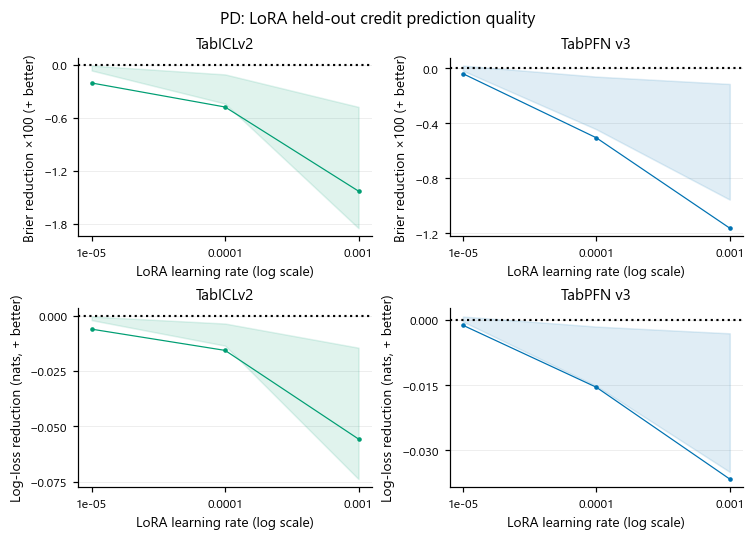

Experiment 8: LoRA prediction-quality effects on held-out credit tables, paired with the original checkpoint of the same base. Positive effects indicate improvement. Lines show equal-table mean effects and shading the table interquartile range, not confidence intervals. Each model uses a common table cohort across all three rates and both displayed metrics, with complete five-fold pairs. RMSE is a fractional reduction relative to the original (in %); Brier reductions are multiplied by 100; log-loss and MAE effects are original minus adapted on their native scales. These summaries describe the declared grid without selecting a best rate on held-out scores.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Bondora Peer-to-Peer,credit,brier_score,-0.000616,0.080427,0.081043,1
1,TabICLv2,0.00001,0.0,True,one_sample,Cobranded,credit,brier_score,-0.000318,0.130724,0.131042,1
2,TabICLv2,0.00001,0.0,True,one_sample,Credit Risk,credit,brier_score,-0.006955,0.049369,0.056324,1
3,TabICLv2,0.00001,0.0,True,one_sample,GMSC,credit,brier_score,-0.000159,0.049082,0.049241,1
4,TabICLv2,0.00001,0.0,True,one_sample,German Credit,credit,brier_score,0.000238,0.162387,0.162149,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.00100,0.0,True,one_sample,PropPD2,credit,brier_score,-0.000215,0.082365,0.082580,1
98,TabPFN v3,0.00100,0.0,True,one_sample,SBA Loans Case,credit,brier_score,-0.009247,0.033251,0.042498,1
99,TabPFN v3,0.00100,0.0,True,one_sample,Taiwan Credit Card,credit,brier_score,-0.001185,0.133059,0.134244,1
100,TabPFN v3,0.00100,0.0,True,one_sample,Thomas,credit,brier_score,-0.009543,0.183508,0.193051,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46905,ood,brier_score,-0.001242,0.040409,0.041651,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46947,ood,brier_score,-0.000449,0.067741,0.068190,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46952,ood,brier_score,-0.000500,0.085743,0.086243,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46956,ood,brier_score,0.000204,0.056575,0.056371,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46905,ood,brier_score,-0.004192,0.040409,0.044601,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46947,ood,brier_score,-0.001836,0.067741,0.069577,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46952,ood,brier_score,-0.009942,0.085743,0.095685,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46956,ood,brier_score,-0.001695,0.056575,0.058270,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46905,ood,brier_score,-0.011752,0.040409,0.052161,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46947,ood,brier_score,-0.007494,0.067741,0.075235,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Bondora Peer-to-Peer,credit,log_loss,-0.001857,0.256125,0.257982,1
1,TabICLv2,0.00001,0.0,True,one_sample,Cobranded,credit,log_loss,-0.001056,0.404901,0.405957,1
2,TabICLv2,0.00001,0.0,True,one_sample,Credit Risk,credit,log_loss,-0.025207,0.176281,0.201488,1
3,TabICLv2,0.00001,0.0,True,one_sample,GMSC,credit,log_loss,-0.000891,0.178190,0.179081,1
4,TabICLv2,0.00001,0.0,True,one_sample,German Credit,credit,log_loss,0.002269,0.496485,0.494216,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.00100,0.0,True,one_sample,PropPD2,credit,log_loss,-0.001244,0.297589,0.298832,1
98,TabPFN v3,0.00100,0.0,True,one_sample,SBA Loans Case,credit,log_loss,-0.029878,0.119508,0.149386,1
99,TabPFN v3,0.00100,0.0,True,one_sample,Taiwan Credit Card,credit,log_loss,-0.004423,0.424775,0.429198,1
100,TabPFN v3,0.00100,0.0,True,one_sample,Thomas,credit,log_loss,-0.034982,0.550369,0.585351,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46905,ood,log_loss,-0.002696,0.157558,0.160255,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46947,ood,log_loss,-0.002454,0.218649,0.221103,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46952,ood,log_loss,0.000022,0.288323,0.288301,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46956,ood,log_loss,0.001325,0.212404,0.211079,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46905,ood,log_loss,-0.014197,0.157558,0.171755,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46947,ood,log_loss,-0.009200,0.218649,0.227849,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46952,ood,log_loss,-0.026186,0.288323,0.314509,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46956,ood,log_loss,-0.009723,0.212404,0.222127,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46905,ood,log_loss,-0.096605,0.157558,0.254163,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46947,ood,log_loss,-0.045620,0.218649,0.264269,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Bondora Peer-to-Peer,credit,ece,-0.001486,0.007652,0.009139,1
1,TabICLv2,0.00001,0.0,True,one_sample,Cobranded,credit,ece,-0.003524,0.015550,0.019074,1
2,TabICLv2,0.00001,0.0,True,one_sample,Credit Risk,credit,ece,0.001475,0.011912,0.010437,1
3,TabICLv2,0.00001,0.0,True,one_sample,GMSC,credit,ece,-0.001574,0.010033,0.011606,1
4,TabICLv2,0.00001,0.0,True,one_sample,German Credit,credit,ece,-0.014567,0.047749,0.062316,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.00100,0.0,True,one_sample,PropPD2,credit,ece,-0.001501,0.017705,0.019207,1
98,TabPFN v3,0.00100,0.0,True,one_sample,SBA Loans Case,credit,ece,-0.004410,0.022170,0.026581,1
99,TabPFN v3,0.00100,0.0,True,one_sample,Taiwan Credit Card,credit,ece,0.000833,0.022960,0.022127,1
100,TabPFN v3,0.00100,0.0,True,one_sample,Thomas,credit,ece,-0.037097,0.046704,0.083802,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46905,ood,ece,-0.000636,0.010737,0.011373,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46947,ood,ece,-0.000952,0.015204,0.016156,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46952,ood,ece,0.001237,0.055028,0.053791,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46956,ood,ece,0.001163,0.020137,0.018974,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46905,ood,ece,-0.007731,0.010737,0.018468,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46947,ood,ece,-0.004261,0.015204,0.019465,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46952,ood,ece,-0.009643,0.055028,0.064672,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46956,ood,ece,-0.005486,0.020137,0.025623,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46905,ood,ece,-0.024879,0.010737,0.035616,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46947,ood,ece,-0.021497,0.015204,0.036702,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Bondora Peer-to-Peer,credit,f1,-0.002752,0.565968,0.563216,1
1,TabICLv2,0.00001,0.0,True,one_sample,Cobranded,credit,f1,-0.000226,0.610091,0.609865,1
2,TabICLv2,0.00001,0.0,True,one_sample,Credit Risk,credit,f1,-0.023936,0.845099,0.821163,1
3,TabICLv2,0.00001,0.0,True,one_sample,GMSC,credit,f1,-0.002179,0.443258,0.441079,1
4,TabICLv2,0.00001,0.0,True,one_sample,German Credit,credit,f1,-0.021892,0.604051,0.582160,1
...,...,...,...,...,...,...,...,...,...,...,...,...
97,TabPFN v3,0.00100,0.0,True,one_sample,PropPD2,credit,f1,-0.004839,0.229332,0.224493,1
98,TabPFN v3,0.00100,0.0,True,one_sample,SBA Loans Case,credit,f1,-0.018733,0.923122,0.904389,1
99,TabPFN v3,0.00100,0.0,True,one_sample,Taiwan Credit Card,credit,f1,-0.000234,0.548195,0.547962,1
100,TabPFN v3,0.00100,0.0,True,one_sample,Thomas,credit,f1,0.008670,0.432436,0.441106,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46905,ood,f1,-0.000039,0.973562,0.973523,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46947,ood,f1,-0.002752,0.686600,0.683848,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46952,ood,f1,0.006061,0.811382,0.817443,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46956,ood,f1,0.003435,0.290409,0.293844,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46905,ood,f1,-0.001530,0.973562,0.972031,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46947,ood,f1,-0.008598,0.686600,0.678002,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46952,ood,f1,-0.007676,0.811382,0.803705,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46956,ood,f1,-0.024930,0.290409,0.265479,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46905,ood,f1,-0.002937,0.973562,0.970624,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46947,ood,f1,-0.021830,0.686600,0.664771,4


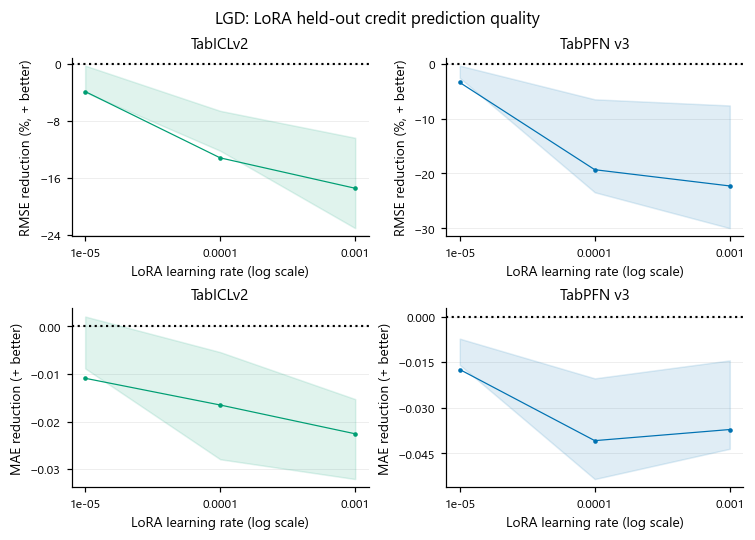

Experiment 8: LoRA prediction-quality effects on held-out credit tables, paired with the original checkpoint of the same base. Positive effects indicate improvement. Lines show equal-table mean effects and shading the table interquartile range, not confidence intervals. Each model uses a common table cohort across all three rates and both displayed metrics, with complete five-fold pairs. RMSE is a fractional reduction relative to the original (in %); Brier reductions are multiplied by 100; log-loss and MAE effects are original minus adapted on their native scales. These summaries describe the declared grid without selecting a best rate on held-out scores.

,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Freddie Mac,credit,rmse,-0.051354,0.249757,0.262561,1
1,TabICLv2,0.00001,0.0,True,one_sample,LendingClub (LGD),credit,rmse,-0.001501,0.125315,0.125506,1
2,TabICLv2,0.00001,0.0,True,one_sample,PropLGD1,credit,rmse,-0.206427,0.249361,0.300822,1
3,TabICLv2,0.00001,0.0,True,one_sample,PropLGD2,credit,rmse,-0.036070,0.141589,0.146691,1
4,TabICLv2,0.00001,0.0,True,one_sample,PropLGD3,credit,rmse,-0.002815,0.291811,0.292627,1
5,TabICLv2,0.00001,0.0,True,one_sample,PropLGD4,credit,rmse,0.001977,0.287164,0.286643,1
6,TabICLv2,0.00001,0.0,True,one_sample,PropLGD5,credit,rmse,-0.005922,0.322237,0.324189,1
7,TabICLv2,0.00001,0.0,True,one_sample,SBA Loans Case (LGD),credit,rmse,-0.008626,0.131757,0.132891,1
8,TabICLv2,0.00010,0.0,True,one_sample,Freddie Mac,credit,rmse,-0.120827,0.249757,0.279913,1
9,TabICLv2,0.00010,0.0,True,one_sample,LendingClub (LGD),credit,rmse,-0.063684,0.125315,0.133194,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46904,ood,rmse,-0.057504,1.105748,1.169309,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46917,ood,rmse,-0.030066,3.786589,3.888568,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46949,ood,rmse,-0.179804,2.963379,3.496156,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46961,ood,rmse,-0.257866,8.980406,11.294545,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46904,ood,rmse,-0.481314,1.105748,1.636544,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46917,ood,rmse,-0.151004,3.786589,4.337520,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46949,ood,rmse,-0.519157,2.963379,4.501740,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46961,ood,rmse,-0.927094,8.980406,17.299909,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46904,ood,rmse,-0.716018,1.105748,1.897003,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46917,ood,rmse,-0.361058,3.786589,5.097899,4


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,Freddie Mac,credit,mae,-0.013890,0.197255,0.211145,1
1,TabICLv2,0.00001,0.0,True,one_sample,LendingClub (LGD),credit,mae,0.002116,0.063667,0.061550,1
2,TabICLv2,0.00001,0.0,True,one_sample,PropLGD1,credit,mae,-0.065314,0.157501,0.222815,1
3,TabICLv2,0.00001,0.0,True,one_sample,PropLGD2,credit,mae,-0.007161,0.098312,0.105472,1
4,TabICLv2,0.00001,0.0,True,one_sample,PropLGD3,credit,mae,0.002379,0.219361,0.216982,1
5,TabICLv2,0.00001,0.0,True,one_sample,PropLGD4,credit,mae,0.002037,0.210988,0.208952,1
6,TabICLv2,0.00001,0.0,True,one_sample,PropLGD5,credit,mae,-0.004961,0.238580,0.243541,1
7,TabICLv2,0.00001,0.0,True,one_sample,SBA Loans Case (LGD),credit,mae,-0.002487,0.080903,0.083390,1
8,TabICLv2,0.00010,0.0,True,one_sample,Freddie Mac,credit,mae,-0.027579,0.197255,0.224834,1
9,TabICLv2,0.00010,0.0,True,one_sample,LendingClub (LGD),credit,mae,-0.006501,0.063667,0.070168,1


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,untuned,trained,partitions
0,TabICLv2,0.00001,0.0,True,one_sample,openml_46904,ood,mae,-0.056924,0.725305,0.782229,4
1,TabICLv2,0.00001,0.0,True,one_sample,openml_46917,ood,mae,-0.153512,2.361429,2.514941,4
2,TabICLv2,0.00001,0.0,True,one_sample,openml_46949,ood,mae,-0.516644,1.747524,2.264168,4
3,TabICLv2,0.00001,0.0,True,one_sample,openml_46961,ood,mae,-1.666035,4.848941,6.514976,4
4,TabICLv2,0.00010,0.0,True,one_sample,openml_46904,ood,mae,-0.350345,0.725305,1.075650,4
5,TabICLv2,0.00010,0.0,True,one_sample,openml_46917,ood,mae,-0.622650,2.361429,2.984079,4
6,TabICLv2,0.00010,0.0,True,one_sample,openml_46949,ood,mae,-1.641919,1.747524,3.389443,4
7,TabICLv2,0.00010,0.0,True,one_sample,openml_46961,ood,mae,-5.683555,4.848941,10.532496,4
8,TabICLv2,0.00100,0.0,True,one_sample,openml_46904,ood,mae,-0.592231,0.725305,1.317536,4
9,TabICLv2,0.00100,0.0,True,one_sample,openml_46917,ood,mae,-1.437211,2.361429,3.798640,4


In [4]:
for run in runs:
    cp.show(sink, ls.plot_secondary(run))
    for metric in (('brier_score', 'log_loss', 'ece', 'f1') if run.track == 'pd' else ('rmse', 'mae')):
        for domain in ('credit', 'ood'):
            report.table(run.track.upper()+' '+domain+' '+metric, ls.benchmark_tables(run, metric, domain))
report.add('3. Probability quality and regression errors', 'Each secondary figure requires the same complete table cohort for every rate and both displayed metrics. Bands show table interquartile ranges, not confidence intervals. RMSE changes are fractional reductions; Brier, log-loss and MAE differences remain on their native scales. Missing or nonfinite values are never filled with zero.')

## 4. Cost and comparison with earlier adaptation recipes

In [5]:
for run in runs:
    report.table(run.track.upper()+' training resources', ls.costs(run))
    reference_cfg = cp.load_train_config(config_path=str(cp.config_path(1, run.track)))
    reference = cp.Campaign(reference_cfg, cp.planned_trials(reference_cfg), run.trajectories.iloc[:0], run.histories.iloc[:0], run.evaluation.iloc[:0])
    report.table(run.track.upper()+' experiment-1 protocol comparison', ls.reference_protocol_audit(run, reference))
report.add('4. Cost and comparison with earlier adaptation recipes', 'Only learning rate 1e-5 overlaps the earlier L2-SP-zero full/frozen grid. In particular, TabICL benchmark precision differs from experiment 1. Earlier scores are therefore not silently pooled into a parameter-count ablation. A direct comparison requires matching base/data hashes, row folds, inference settings and remaining training protocol. Rank and alpha are fixed, so these results do not estimate the best achievable LoRA performance. Overlapping training corpora, related sources and the small non-credit panel limit independence and generality.')

,trial_name,base,learning_rate,partition,seed,status,optimizer_selected_lora_parameters,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,relative_effective_qv_displacement
0,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00001,0,42,OK,860160,54013304,195157151,5178.202935,1.438390,83.683,0.024076
1,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00010,0,42,OK,860160,54013304,195157151,5174.528606,1.437369,83.683,0.281339
2,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,0,42,OK,860160,54013304,195157151,5177.802615,1.438279,83.683,1.831706
3,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,0,42,OK,466944,28019202,195157151,6043.083728,1.678634,25.476,0.010088
4,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00010,0,42,OK,466944,28019202,195157151,5940.545044,1.650151,25.476,0.058023
5,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00100,0,42,OK,466944,28019202,195157151,5926.280326,1.646189,25.476,0.505089
6,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00001,1,42,OK,860160,54013304,179895410,5039.597074,1.399888,83.683,0.025509
7,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00010,1,42,OK,860160,54013304,179895410,4982.094286,1.383915,83.683,0.195434
8,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,1,42,OK,860160,54013304,179895410,4969.911524,1.380531,83.683,1.878117
9,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,1,42,OK,466944,28019202,179895410,5646.398277,1.568444,25.476,0.010145


,check,experiment1,experiment8,matches
0,seed,42,42,True
1,train.target_total_steps,10000,10000,True
2,train.max_rows_per_step,None,None,True
3,train.context_sampling,balanced,balanced,True
4,train.amp,True,True,True
5,optimizer.weight_decay,0.0,0.0,True
6,scheduler,"{'warmup_fraction': 0.1, 'min_lr_fraction': 0.05}","{'warmup_fraction': 0.1, 'min_lr_fraction': 0.05}",True
7,corpus.n_folds,4,4,True
8,corpus.split_seed,1729,1729,True
9,evaluation.tabicl_inference_options,None,"{'use_amp': False, 'use_fa3': False}",False


,trial_name,base,learning_rate,partition,seed,status,optimizer_selected_lora_parameters,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,relative_effective_qv_displacement
0,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00001,0,42,OK,860160,59135104,82784961,2135.081013,0.593078,32.567,0.034434
1,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00010,0,42,OK,860160,59135104,82784961,2038.587626,0.566274,32.567,0.176341
2,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,0,42,OK,860160,59135104,82784961,2014.511486,0.559587,32.567,1.421922
3,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,0,42,OK,466944,29011935,82784961,1990.954082,0.553043,10.545,0.020050
4,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00010,0,42,OK,466944,29011935,82784961,2012.639926,0.559067,10.545,0.109985
5,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00100,0,42,OK,466944,29011935,82784961,2058.362082,0.571767,10.545,8.639638
6,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00001,1,42,OK,860160,59135104,24755261,1245.984178,0.346107,14.673,0.035532
7,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00010,1,42,OK,860160,59135104,24755261,1327.134023,0.368648,14.673,0.194100
8,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,1,42,OK,860160,59135104,24755261,1321.105155,0.366974,14.673,1.506811
9,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,1,42,OK,466944,29011935,24755261,898.383233,0.249551,4.144,0.016830


,check,experiment1,experiment8,matches
0,seed,42,42,True
1,train.target_total_steps,10000,10000,True
2,train.max_rows_per_step,None,None,True
3,train.context_sampling,stratified,stratified,True
4,train.amp,True,True,True
5,optimizer.weight_decay,0.0,0.0,True
6,scheduler,"{'warmup_fraction': 0.1, 'min_lr_fraction': 0.05}","{'warmup_fraction': 0.1, 'min_lr_fraction': 0.05}",True
7,corpus.n_folds,4,4,True
8,corpus.split_seed,1729,1729,True
9,evaluation.tabicl_inference_options,None,"{'use_amp': False, 'use_fa3': False}",False


## Complete text summary

All displayed values, tables and captions in section order.

In [6]:
print(report.summary(sink))

Experiment 8: LoRA transfer and retention

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Original versus LoRA comparisons describe the fixed experiment-8 recipe; no best-rate selection is performed on the reported held-out scores.

1. Checkpoint and paired evaluation coverage
Every trained/original comparison requires all five finite outer folds. Non-credit tables also require all four training partitions. A pending roster or absent figure is not a zero effect and does not indicate whether a remote job is running.

Table: PD protocol
CSV (first column: row index)
row,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,PD
2,Adaptation,Low-rank updates to all attention query/value projections; base weights fixed
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA product FP32
8,Lea